Importação das bibliotecas

In [2]:
from pathlib import Path
import urllib.request
import zipfile
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

Carregar e usar os dados

In [3]:
class CarregadorDados:

    def __init__(self, url, arquivos, pasta="data"):
        self.url = url
        self.arquivos = arquivos
        self.pasta = Path(pasta)
        self.pasta_raw = self.pasta / "raw"
        self.pasta_processed = self.pasta / "processed"
        self.pasta_raw.mkdir(parents=True, exist_ok=True)
        self.pasta_processed.mkdir(parents=True, exist_ok=True)

    def baixar(self):
        zip_path = self.pasta / "occupancy_data.zip"

        try:
            urllib.request.urlretrieve(self.url, zip_path)
        except Exception as erro:
            raise RuntimeError(
                "Não foi possível baixar a base. Baixe o zip na página da UCI "
                "e extraia os arquivos .txt em data/raw."
            ) from erro

        with zipfile.ZipFile(zip_path) as z:
            z.extractall(self.pasta_raw)

        zip_path.unlink()

    def carregar(self):
        faltando = [a for a in self.arquivos if not (self.pasta_raw / a).exists()]

        if faltando:
            print("Baixando:", faltando)
            self.baixar()

        return {
            Path(a).stem: pd.read_csv(self.pasta_raw / a).reset_index(drop=True)
            for a in self.arquivos
        }


carregador = CarregadorDados(
    url="https://archive.ics.uci.edu/ml/machine-learning-databases/00357/occupancy_data.zip",
    arquivos=["datatraining.txt", "datatest.txt", "datatest2.txt"],
    pasta="../data"
)

dfs = carregador.carregar()
df = dfs["datatest"]

print("Base de dados carregada com sucesso!")
df.head()

Base de dados carregada com sucesso!


,date,Temperature,Humidity,Light,CO2,HumidityRatio,Occupancy
0,2015-02-02 14:19:00,23.7000,26.272,585.200000,749.200000,0.004764,1
1,2015-02-02 14:19:59,23.7180,26.290,578.400000,760.400000,0.004773,1
2,2015-02-02 14:21:00,23.7300,26.230,572.666667,769.666667,0.004765,1
3,2015-02-02 14:22:00,23.7225,26.125,493.750000,774.750000,0.004744,1
4,2015-02-02 14:23:00,23.7540,26.200,488.600000,779.000000,0.004767,1


# Fase 1: Análise Exploratória (EDA)

Nesta fase olho para a estrutura da base, o resumo estatístico e o comportamento das variáveis, para decidir como tratar os dados e modelar nas próximas fases.

## Dimensões, tipos e resumo estatístico

In [4]:
print("Linhas e colunas:", df.shape)
print()
df.info()
print()
print(df.describe())

Linhas e colunas: (2665, 7)

<class 'pandas.DataFrame'>
RangeIndex: 2665 entries, 0 to 2664
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   date           2665 non-null   str    
 1   Temperature    2665 non-null   float64
 2   Humidity       2665 non-null   float64
 3   Light          2665 non-null   float64
 4   CO2            2665 non-null   float64
 5   HumidityRatio  2665 non-null   float64
 6   Occupancy      2665 non-null   int64  
dtypes: float64(5), int64(1), str(1)
memory usage: 145.9 KB

       Temperature     Humidity        Light          CO2  HumidityRatio  \
count  2665.000000  2665.000000  2665.000000  2665.000000    2665.000000   
mean     21.433876    25.353937   193.227556   717.906470       0.004027   
std       1.028024     2.436842   250.210906   292.681718       0.000611   
min      20.200000    22.100000     0.000000   427.500000       0.003303   
25%      20.650000    23.260000     0.0

## Coluna date

A base tem uma coluna com a data e a hora de cada leitura. Antes de decidir o que fazer com ela, confiro o formato e o período coberto.

In [5]:
df["date"] = pd.to_datetime(df["date"])

print(df["date"].min(), "até", df["date"].max())
print(df["date"].diff().value_counts().head())

2015-02-02 14:19:00 até 2015-02-04 10:43:00
date
0 days 00:01:00    1596
0 days 00:00:59     534
0 days 00:01:01     534
Name: count, dtype: int64


A coluna estava como texto e foi convertida para datetime.
Os dados cobrem de 02/02/2015 às 14h19 até 04/02/2015 às 10h43, cerca de dois dias, com uma leitura por minuto e sem lacunas (os intervalos de 59 e 61 segundos são variações pequenas do relógio do sensor).

Vou descartar a coluna porque o KNN e a árvore de decisão serão treinados só com as variáveis numéricas dos sensores, e a data indica o momento da leitura, não o comportamento do ambiente.

In [6]:
df = df.drop(columns="date")
df.head()

,Temperature,Humidity,Light,CO2,HumidityRatio,Occupancy
0,23.7000,26.272,585.200000,749.200000,0.004764,1
1,23.7180,26.290,578.400000,760.400000,0.004773,1
2,23.7300,26.230,572.666667,769.666667,0.004765,1
3,23.7225,26.125,493.750000,774.750000,0.004744,1
4,23.7540,26.200,488.600000,779.000000,0.004767,1


## Distribuição das variáveis

Histogramas das variáveis preditoras, para ver a forma das distribuições e se há concentração de valores.

Dicionário para renomear os títulos do gráfico sem modificar o nome das variáveis.

In [7]:
nomes = {
    "Temperature": "Temperatura (°C)",
    "Humidity": "Umidade (%)",
    "Light": "Luminosidade (lux)",
    "CO2": "CO2 (ppm)",
    "HumidityRatio": "Razão de umidade",
    "Occupancy": "Ocupação"
}

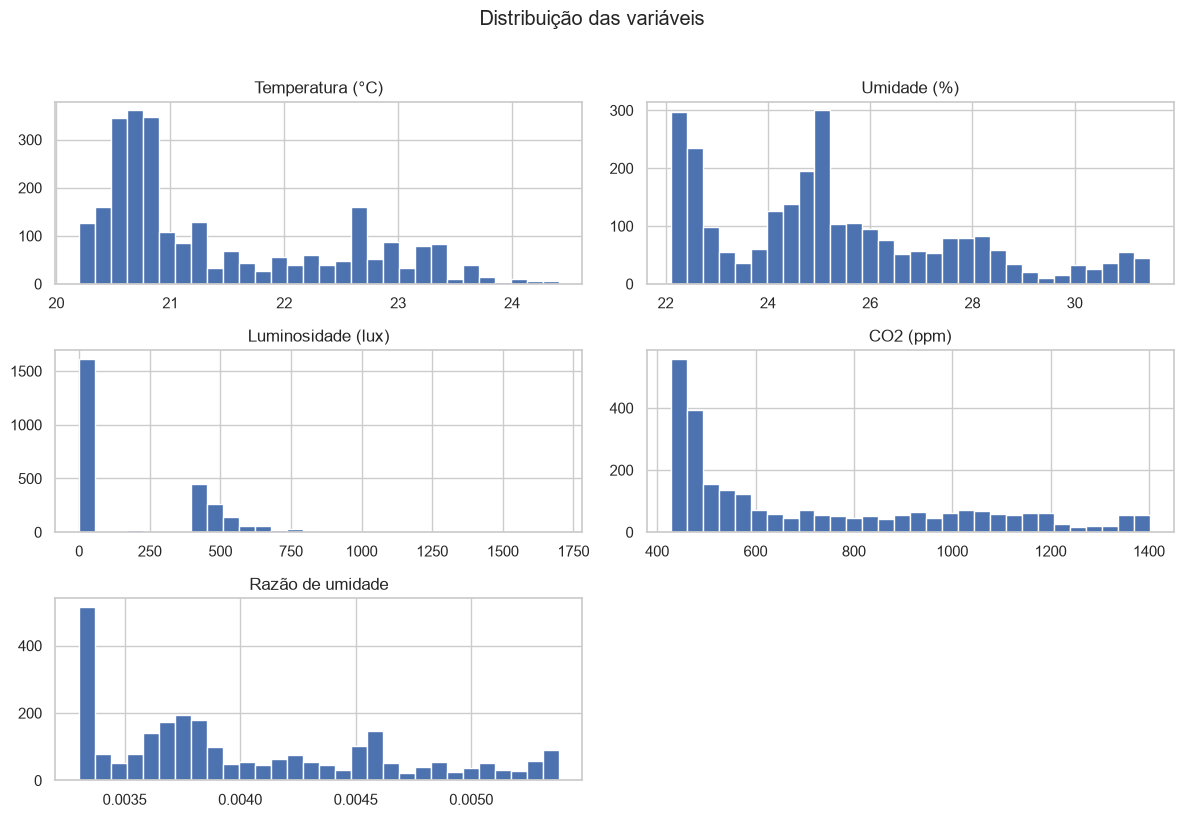

In [8]:
colunas = ["Temperature", "Humidity", "Light", "CO2", "HumidityRatio"]

df[colunas].rename(columns=nomes).hist(bins=30, figsize=(12, 8))
plt.suptitle("Distribuição das variáveis", y=1.02)
plt.tight_layout()
plt.show()

## Proporção das classes da variável alvo

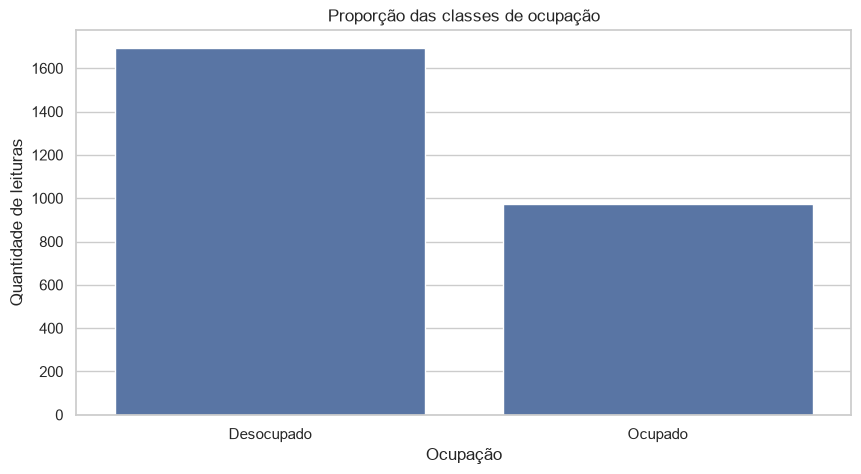

Occupancy
0    0.635272
1    0.364728
Name: proportion, dtype: float64


In [9]:
sns.countplot(data=df, x="Occupancy")
plt.title("Proporção das classes de ocupação")
plt.xlabel("Ocupação")
plt.ylabel("Quantidade de leituras")
plt.xticks([0, 1], ["Desocupado", "Ocupado"])
plt.show()

print(df["Occupancy"].value_counts(normalize=True))

## Correlação entre as variáveis

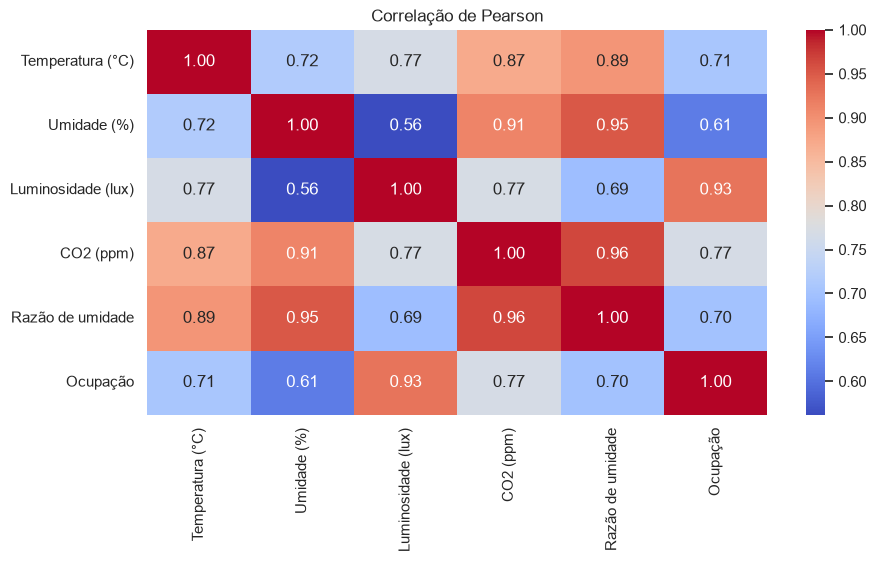

In [10]:
corr = df[colunas + ["Occupancy"]].corr()
corr = corr.rename(index=nomes, columns=nomes)

sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlação de Pearson")
plt.show()

## Análise dos resultados

**Classes.** A base tem cerca de 64% de leituras com ambiente desocupado e 36% com ambiente ocupado.
Há desbalanceamento moderado, então a divisão treino e teste será estratificada para manter essa proporção nos dois conjuntos.

**Relação com a ocupação.** A luminosidade é a variável mais associada à ocupação (correlação de 0,93), seguida pelo CO2 (0,77), pela temperatura (0,71), pela razão de umidade (0,70) e pela umidade (0,61).
Todas as correlações são positivas: ambientes ocupados têm mais luz, mais CO2 e mais calor.

**Distribuições.** A luminosidade se divide em dois grupos, um perto de zero (luzes apagadas) e outro entre 400 e 600 lux, com poucos valores acima de 1000.
O CO2 se concentra nos valores baixos, com cauda longa até cerca de 1400 ppm.
Temperatura e umidade são mais espalhadas, em faixas estreitas (20 a 24,5 °C e 22 a 31%).
A cauda de luminosidade e CO2 indica que a Fase 2 deve verificar os outliers.

**Variáveis redundantes.** A razão de umidade tem correlação de 0,96 com o CO2 e de 0,95 com a umidade, o que era esperado, pois é derivada de temperatura e umidade. Isso indica informação repetida entre as variáveis, mas não impede o uso nos modelos.

**Estratégia de modelagem.** As escalas são muito diferentes (luminosidade passa de 1500, razão de umidade fica perto de 0,004).
O KNN, baseado em distância, precisa de escalonamento, e a árvore de decisão não. A luminosidade deve ser a variável mais importante nos dois modelos.

# Fase 2: Limpeza e Tratamento de Dados

Nesta fase removo linhas duplicadas, verifico valores ausentes e analiso a presença de outliers nas variáveis explicativas.

In [11]:
print("Linhas duplicadas:", df.duplicated().sum())
df = df.drop_duplicates()
print("Linhas após a remoção:", df.shape[0])

Linhas duplicadas: 82
Linhas após a remoção: 2583


In [12]:
print(df.isna().sum())
print()
print(df.skew())

Temperature      0
Humidity         0
Light            0
CO2              0
HumidityRatio    0
Occupancy        0
dtype: int64

Temperature      0.801129
Humidity         0.647466
Light            0.711140
CO2              0.744193
HumidityRatio    0.613974
Occupancy        0.510943
dtype: float64


## Valores ausentes

A base não tem valores ausentes em nenhuma coluna, então não foi necessário imputar.
Se houvesse, eu usaria a mediana e não a média, porque luminosidade e CO2 têm distribuição assimétrica (visível nos histogramas e nos valores de assimetria acima), e a mediana não é puxada pelos valores extremos.
Como não há imputação, também não existe risco de vazamento de dados antes da divisão treino e teste.

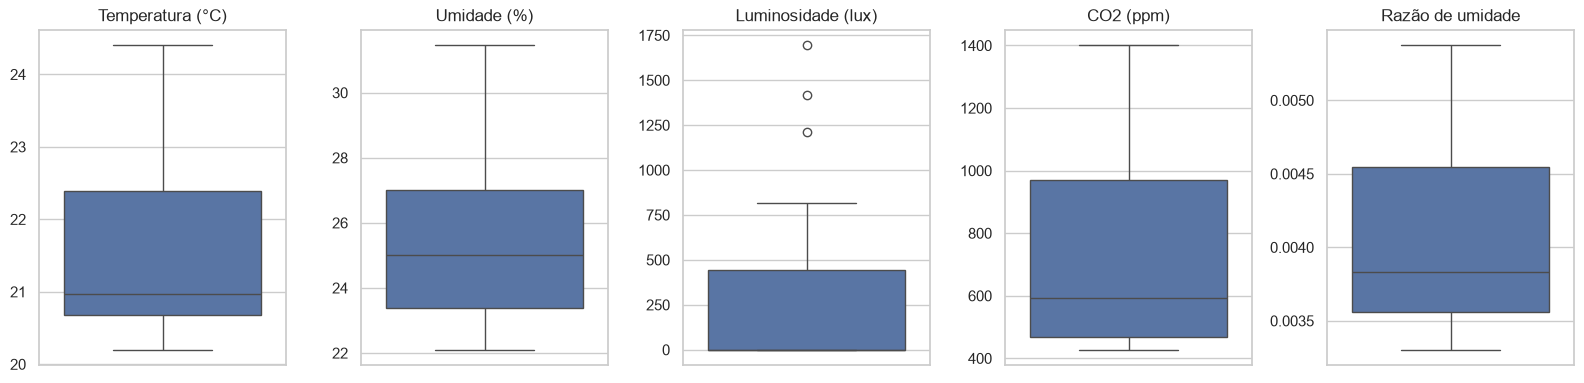

In [13]:
fig, eixos = plt.subplots(1, 5, figsize=(16, 4))

for eixo, col in zip(eixos, colunas):
    sns.boxplot(y=df[col], ax=eixo)
    eixo.set_title(nomes[col])
    eixo.set_ylabel("")

plt.tight_layout()
plt.show()

In [14]:
q1 = df[colunas].quantile(0.25)
q3 = df[colunas].quantile(0.75)
iqr = q3 - q1

fora = (df[colunas] < q1 - 1.5 * iqr) | (df[colunas] > q3 + 1.5 * iqr)
print(fora.sum())

Temperature      0
Humidity         0
Light            3
CO2              0
HumidityRatio    0
dtype: int64
